In [1]:
import pandas as pd
import os


In [2]:
data_dir = "../data"

files = [file for file in os.listdir(data_dir) if file.endswith(".XPT")]
print(files)  # To check all files detected


[]


In [3]:
import os

print(os.getcwd())  # Print current working directory
print(os.listdir()) # Show all files/folders in this directory


c:\Users\HP\ai-health-assistant\data
['BMX_J.xpt', 'BPX_J.xpt', 'CBC_J.xpt', 'DEMO_J.xpt', 'DR1IFF_J.xpt', 'DR1TOT_J.xpt', 'DR2IFF_J.xpt', 'DR2TOT_J.xpt', 'GHB_J.xpt', 'GLU_J.xpt', 'HDL_J.xpt', 'load_combine_nhanes.ipynb', 'nhanes_cleaned.csv', 'nhanes_full.csv', 'TCHOL_J.xpt', 'TRIGLY_J.xpt', 'WESAD']


In [4]:
import os
import pandas as pd

# Step 1: Set data directory
data_dir = "../data"

# Step 2: List .xpt files
files = [file for file in os.listdir(data_dir) if file.lower().endswith(".xpt")]
print(f"Found {len(files)} files:", files)

# Step 3: Load each file into a DataFrame and store in a dictionary
data_frames = {}
for file in files:
    path = os.path.join(data_dir, file)
    try:
        df = pd.read_sas(path, format='xport', encoding='utf-8')
        key = file.replace(".xpt", "").upper()
        data_frames[key] = df
        print(f"Loaded: {file} -> {df.shape}")
    except Exception as e:
        print(f"Failed to load {file}: {e}")

# Example: Access one of the loaded DataFrames
data_frames['DEMO_J'].head()


Found 13 files: ['BMX_J.xpt', 'BPX_J.xpt', 'CBC_J.xpt', 'DEMO_J.xpt', 'DR1IFF_J.xpt', 'DR1TOT_J.xpt', 'DR2IFF_J.xpt', 'DR2TOT_J.xpt', 'GHB_J.xpt', 'GLU_J.xpt', 'HDL_J.xpt', 'TCHOL_J.xpt', 'TRIGLY_J.xpt']
Loaded: BMX_J.xpt -> (8704, 21)
Loaded: BPX_J.xpt -> (8704, 21)
Loaded: CBC_J.xpt -> (8366, 22)
Loaded: DEMO_J.xpt -> (9254, 46)
Loaded: DR1IFF_J.xpt -> (112683, 84)
Loaded: DR1TOT_J.xpt -> (8704, 168)
Loaded: DR2IFF_J.xpt -> (93500, 84)
Loaded: DR2TOT_J.xpt -> (8704, 85)
Loaded: GHB_J.xpt -> (6401, 2)
Loaded: GLU_J.xpt -> (3036, 4)
Loaded: HDL_J.xpt -> (7435, 3)
Loaded: TCHOL_J.xpt -> (7435, 3)
Loaded: TRIGLY_J.xpt -> (3036, 10)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVPSU,SDMVSTRA,INDHHIN2,INDFMIN2,INDFMPIR
0,93703.0,10.0,2.0,2.0,2.0,NaN,5.0,6.0,2.0,27.0,...,3.0,1.0,3.0,9246.491865,8539.731348,2.0,145.0,15.0,15.0,5.00
1,93704.0,10.0,2.0,1.0,2.0,NaN,3.0,3.0,1.0,33.0,...,3.0,1.0,2.0,37338.768343,42566.614750,1.0,143.0,15.0,15.0,5.00
2,93705.0,10.0,2.0,2.0,66.0,NaN,4.0,4.0,2.0,NaN,...,1.0,2.0,NaN,8614.571172,8338.419786,2.0,145.0,3.0,3.0,0.82
3,93706.0,10.0,2.0,1.0,18.0,NaN,5.0,6.0,2.0,222.0,...,3.0,1.0,2.0,8548.632619,8723.439814,2.0,134.0,NaN,NaN,NaN
4,93707.0,10.0,2.0,1.0,13.0,NaN,5.0,7.0,2.0,158.0,...,2.0,1.0,3.0,6769.344567,7064.609730,1.0,138.0,10.0,10.0,1.88


All these datasets share the common key: SEQN (participant ID)

In [5]:
# Start with DEMO_J to include gender
combined_df = data_frames['DEMO_J']

# Merge the rest of the files
merge_keys = ['BMX_J', 'BPX_J', 'DR1TOT_J', 'DR2TOT_J', 'HDL_J', 'TCHOL_J',
              'TRIGLY_J', 'GLU_J', 'GHB_J', 'CBC_J']

for key in merge_keys:
    df = data_frames.get(key)
    if df is not None:
        combined_df = pd.merge(combined_df, df, on='SEQN', how='left')
        print(f"Merged with {key}: {combined_df.shape}")
        

# View result
combined_df.head()


Merged with BMX_J: (9254, 66)
Merged with BPX_J: (9254, 86)
Merged with DR1TOT_J: (9254, 253)
Merged with DR2TOT_J: (9254, 337)
Merged with HDL_J: (9254, 339)
Merged with TCHOL_J: (9254, 341)
Merged with TRIGLY_J: (9254, 350)
Merged with GLU_J: (9254, 353)
Merged with GHB_J: (9254, 354)
Merged with CBC_J: (9254, 375)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,LBXRBCSI,LBXHGB,LBXHCT,LBXMCVSI,LBXMCHSI,LBXMC,LBXRDW,LBXPLTSI,LBXMPSI,LBXNRBC
0,93703.0,10.0,2.0,2.0,2.0,NaN,5.0,6.0,2.0,27.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,10.0,2.0,1.0,2.0,NaN,3.0,3.0,1.0,33.0,...,4.25,13.1,37.0,87.0,30.8,35.4,12.8,239.0,8.6,1.000000e-01
2,93705.0,10.0,2.0,2.0,66.0,NaN,4.0,4.0,2.0,NaN,...,5.48,11.9,36.7,67.0,21.7,32.4,15.6,309.0,7.9,5.397605e-79
3,93706.0,10.0,2.0,1.0,18.0,NaN,5.0,6.0,2.0,222.0,...,5.24,16.3,47.0,89.7,31.1,34.7,12.2,233.0,6.6,5.397605e-79
4,93707.0,10.0,2.0,1.0,13.0,NaN,5.0,7.0,2.0,158.0,...,5.02,14.5,42.1,83.9,28.9,34.4,13.6,348.0,8.5,2.000000e-01


In [6]:
# Check missing values
missing = combined_df.isnull().sum()
missing[missing > 0].sort_values(ascending=False).head(20)


BMIHEAD     9254
DRQSDT5     9252
DRQSDT6     9250
DRD370PQ    9248
DRD370JQ    9247
DRQSDT12    9244
DRD350JQ    9242
DRQSDT11    9238
DRD370LQ    9232
DRQSDT8     9231
BMIRECUM    9230
DRQSDT10    9228
DRD370QQ    9219
DRQSDT4     9214
DRQSDT91    9210
DRD370SQ    9193
DRD370OQ    9172
DRQSDT9     9169
DRD350CQ    9161
DRQSDT2     9159
dtype: int64

In [7]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False).head(20)


LBDBANO     843
LBDLYMNO    843
LBXLYPCT    843
LBDEONO     843
LBDNENO     843
LBDMONO     843
LBXNRBC     843
LBXBAPCT    843
LBXEOPCT    843
LBXNEPCT    843
LBXMOPCT    843
LBXRBCSI    838
LBXHGB      838
LBXHCT      838
LBXMCVSI    838
LBXMCHSI    838
LBXMC       838
LBXRDW      838
LBXPLTSI    838
LBXMPSI     838
dtype: int64

In [ ]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False).head(20)


LBDBANO     843
LBDLYMNO    843
LBXLYPCT    843
LBDEONO     843
LBDNENO     843
LBDMONO     843
LBXNRBC     843
LBXBAPCT    843
LBXEOPCT    843
LBXNEPCT    843
LBXMOPCT    843
LBXRBCSI    838
LBXHGB      838
LBXHCT      838
LBXMCVSI    838
LBXMCHSI    838
LBXMC       838
LBXRDW      838
LBXPLTSI    838
LBXMPSI     838
dtype: int64

In [8]:
# Drop columns with >50% missing data
threshold = len(df) * 0.5
df = df.dropna(thresh=threshold, axis=1)
print(f"Remaining columns: {df.shape[1]}")


Remaining columns: 22


In [9]:
# Drop rows with any missing values
df_cleaned = df.dropna()
print(f"Final shape after dropping rows: {df_cleaned.shape}")


Final shape after dropping rows: (7519, 22)


In [10]:
# Step 1: Select relevant columns and drop missing rows
relevant_columns = [
    'SEQN', 'RIAGENDR', 'LBXHGB', 'LBXHCT', 'LBXRBCSI', 'LBXMCVSI',
    'LBXMCHSI', 'LBXMC', 'LBXRDW', 'LBXPLTSI', 'LBXWBCSI',
    'LBXLYPCT', 'LBXMOPCT', 'LBXNEPCT', 'LBXEOPCT', 'LBXBAPCT',
    'LBDLYMNO', 'LBDMONO', 'LBDNENO', 'LBDEONO', 'LBDBANO', 'LBXNRBC'
]

df = combined_df[relevant_columns].dropna()

# ✅ Step 2: Classify anemia using gender and hemoglobin
def classify_anemia(row):
    if row['RIAGENDR'] == 1:  # Male
        return 1 if row['LBXHGB'] < 13 else 0
    elif row['RIAGENDR'] == 2:  # Female
        return 1 if row['LBXHGB'] < 12 else 0
    return 0  # Unknown

df['Anemia'] = df.apply(classify_anemia, axis=1)


In [11]:
df.to_csv("../data/nhanes_cleaned.csv", index=False)



In [12]:
df_cleaned.columns


Index(['SEQN', 'LBXWBCSI', 'LBXLYPCT', 'LBXMOPCT', 'LBXNEPCT', 'LBXEOPCT',
       'LBXBAPCT', 'LBDLYMNO', 'LBDMONO', 'LBDNENO', 'LBDEONO', 'LBDBANO',
       'LBXRBCSI', 'LBXHGB', 'LBXHCT', 'LBXMCVSI', 'LBXMCHSI', 'LBXMC',
       'LBXRDW', 'LBXPLTSI', 'LBXMPSI', 'LBXNRBC'],
      dtype='object')

EDA

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../data/nhanes_cleaned.csv")


# Show basic info
print(df.shape)
df.head()


(7519, 23)


,SEQN,RIAGENDR,LBXHGB,LBXHCT,LBXRBCSI,LBXMCVSI,LBXMCHSI,LBXMC,LBXRDW,LBXPLTSI,...,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,LBDMONO,LBDNENO,LBDEONO,LBDBANO,LBXNRBC,Anemia
0,93704.0,1.0,13.1,37.0,4.25,87.0,30.8,35.4,12.8,239.0,...,42.6,1.0,0.7,3.5,0.6,3.2,0.1,1.000000e-01,1.000000e-01,0
1,93705.0,2.0,11.9,36.7,5.48,67.0,21.7,32.4,15.6,309.0,...,48.8,2.9,1.0,3.4,0.6,4.2,0.2,1.000000e-01,5.397605e-79,1
2,93706.0,1.0,16.3,47.0,5.24,89.7,31.1,34.7,12.2,233.0,...,61.4,4.3,0.8,1.5,0.6,3.7,0.3,5.397605e-79,5.397605e-79,0
3,93707.0,1.0,14.5,42.1,5.02,83.9,28.9,34.4,13.6,348.0,...,54.7,1.6,0.5,4.2,0.7,6.1,0.2,1.000000e-01,2.000000e-01,0
4,93708.0,2.0,13.2,39.9,4.59,86.8,28.8,33.1,13.4,226.0,...,59.4,2.0,0.7,1.9,0.4,3.6,0.1,5.397605e-79,2.000000e-01,0


In [14]:
df.describe()


,SEQN,RIAGENDR,LBXHGB,LBXHCT,LBXRBCSI,LBXMCVSI,LBXMCHSI,LBXMC,LBXRDW,LBXPLTSI,...,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,LBDMONO,LBDNENO,LBDEONO,LBDBANO,LBXNRBC,Anemia
count,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,7519.000000,...,7519.000000,7.519000e+03,7519.000000,7519.000000,7519.000000,7519.000000,7.519000e+03,7.519000e+03,7.519000e+03,7519.000000
mean,98306.385424,1.511903,13.726333,40.848810,4.733253,86.569411,29.076766,33.569996,13.774185,259.274638,...,54.088709,2.974598e+00,0.755034,2.501982,0.587937,4.035111,2.155473e-01,5.032584e-02,8.493151e-02,0.159064
std,2670.825828,0.499892,1.508594,4.163139,0.479825,6.584061,2.534025,0.932231,1.267684,70.680963,...,11.345297,2.333453e+00,0.329761,4.317595,0.215061,1.732280,1.863928e-01,5.203584e-02,8.304105e-02,0.365760
min,93704.000000,1.000000,6.400000,23.000000,2.320000,35.400000,12.400000,25.200000,11.300000,8.000000,...,8.400000,5.397605e-79,0.100000,0.400000,0.100000,0.400000,5.397605e-79,5.397605e-79,5.397605e-79,0.000000
25%,95993.500000,1.000000,12.800000,38.000000,4.420000,82.900000,27.800000,33.000000,13.000000,211.000000,...,47.400000,1.500000e+00,0.500000,1.800000,0.500000,2.800000,1.000000e-01,5.397605e-79,5.397605e-79,0.000000
50%,98308.000000,2.000000,13.700000,40.700000,4.710000,87.100000,29.300000,33.600000,13.500000,251.000000,...,55.100000,2.400000e+00,0.700000,2.300000,0.600000,3.800000,2.000000e-01,5.397605e-79,1.000000e-01,0.000000
75%,100615.500000,2.000000,14.700000,43.600000,5.030000,90.900000,30.700000,34.200000,14.200000,300.000000,...,61.900000,3.700000e+00,0.900000,2.900000,0.700000,4.900000,3.000000e-01,1.000000e-01,1.000000e-01,0.000000
max,102956.000000,2.000000,19.900000,58.800000,7.840000,114.600000,39.200000,38.300000,29.200000,818.000000,...,92.800000,2.910000e+01,4.800000,358.800000,6.700000,35.200000,3.200000e+00,5.000000e-01,2.000000e+00,1.000000


In [15]:
df.isnull().sum()


SEQN        0
RIAGENDR    0
LBXHGB      0
LBXHCT      0
LBXRBCSI    0
LBXMCVSI    0
LBXMCHSI    0
LBXMC       0
LBXRDW      0
LBXPLTSI    0
LBXWBCSI    0
LBXLYPCT    0
LBXMOPCT    0
LBXNEPCT    0
LBXEOPCT    0
LBXBAPCT    0
LBDLYMNO    0
LBDMONO     0
LBDNENO     0
LBDEONO     0
LBDBANO     0
LBXNRBC     0
Anemia      0
dtype: int64

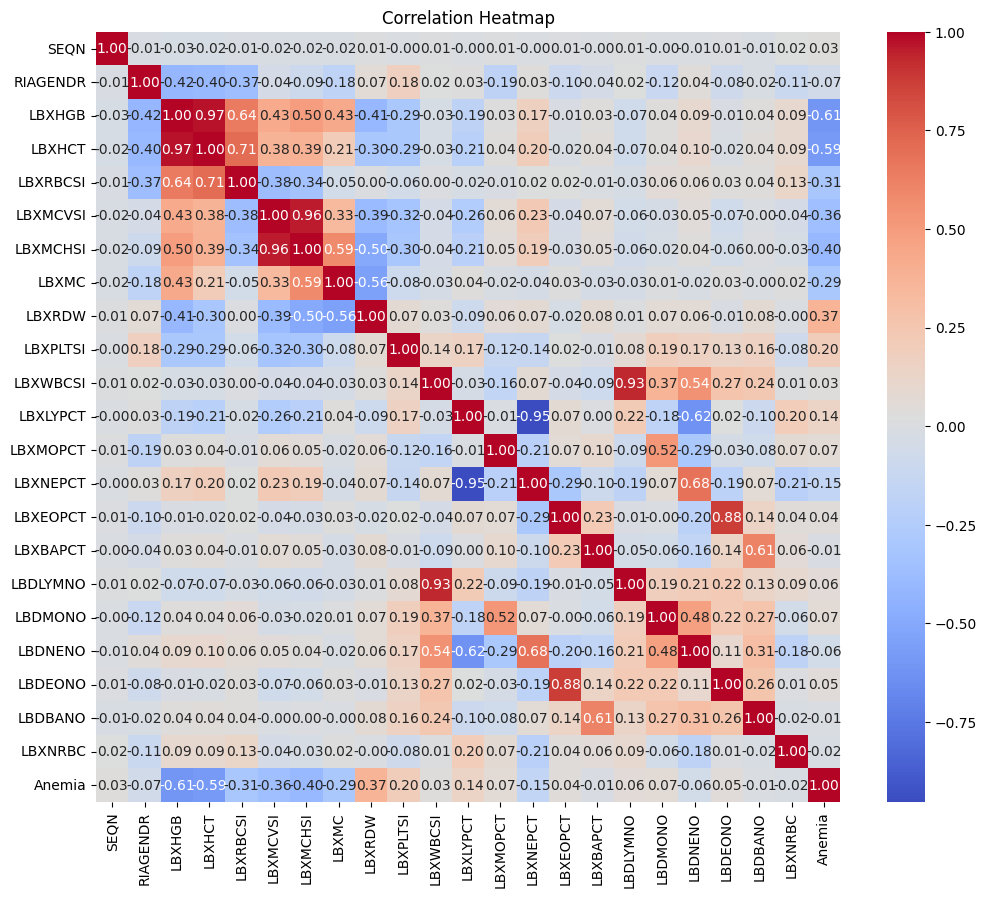

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


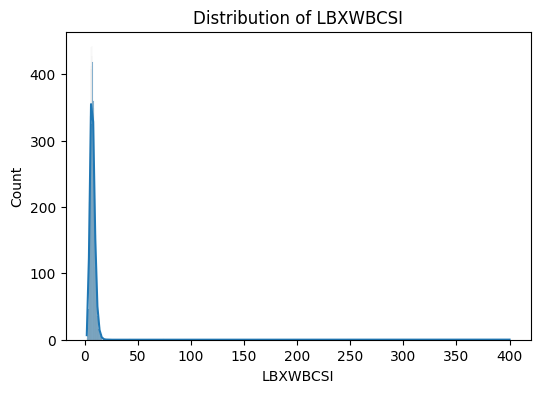

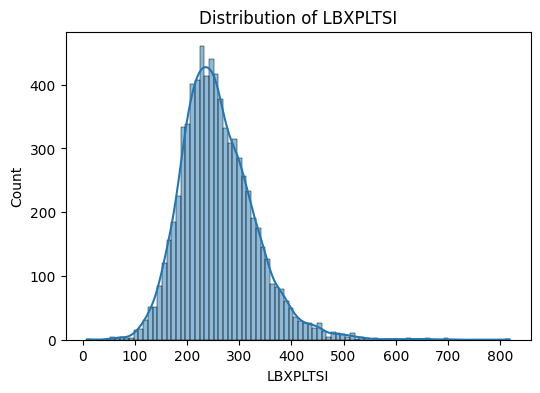

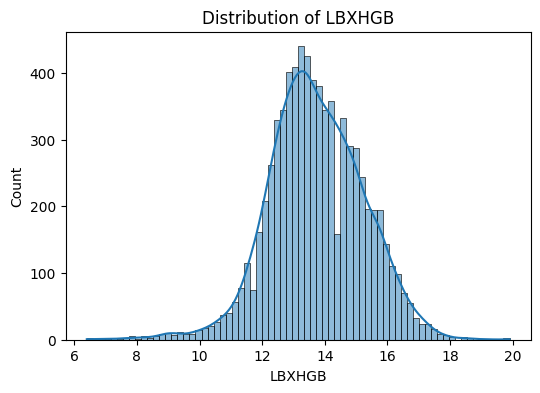

In [17]:
for col in ['LBXWBCSI', 'LBXPLTSI', 'LBXHGB']:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


Box plots for outliers

In [ ]:
for col in ['LBXWBCSI', 'LBXPLTSI', 'LBXHGB']:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()


img ![alt text](image.png)

1. Boxplot of LBXWBCSI:
Median: The median is located at a relatively low value, around 50 on the x-axis, suggesting the central tendency of LBXWBCSI is low.
Spread: The box is relatively narrow, indicating that the middle 50% of the data for LBXWBCSI is quite clustered. The whiskers extend further to the right than to the left.
Skewness: The median line is closer to the bottom (left side) of the box, and the upper whisker is longer, suggesting a positive (right) skewness in the distribution of LBXWBCSI.
Outliers: There are several data points plotted as circles far to the right of the upper whisker, indicating the presence of high outliers in the LBXWBCSI data. 
2. Boxplot of LBXPLTSI:
Median: The median is located near the center of the box, around 250-300 on the x-axis, indicating the central value for LBXPLTSI.
Spread: The box representing the IQR is relatively wide compared to LBXWBCSI, suggesting a greater spread or variability in the middle 50% of LBXPLTSI values. The whiskers also indicate a broader range of data.
Skewness: The median line is close to the center of the box, and the whiskers appear to be of roughly similar length, suggesting a more symmetrical distribution for LBXPLTSI compared to LBXWBCSI.
Outliers: There are a few outlier points to the right of the upper whisker, indicating some high extreme values in the LBXPLTSI data. 
3. Boxplot of LBXHGB:
Median: The median is located within the box, slightly to the left of the center, indicating the central tendency for LBXHGB.
Spread: The box and whiskers show a moderate spread in the data values for LBXHGB.
Skewness: The position of the median within the box and the relative lengths of the whiskers suggest a slight negative (left) skewness in the distribution of LBXHGB.
Outliers: Similar to LBXPLTSI, there are a few outlier points located on both sides (left and right) of the whiskers, suggesting the presence of both low and high extreme values in the LBXHGB data. 

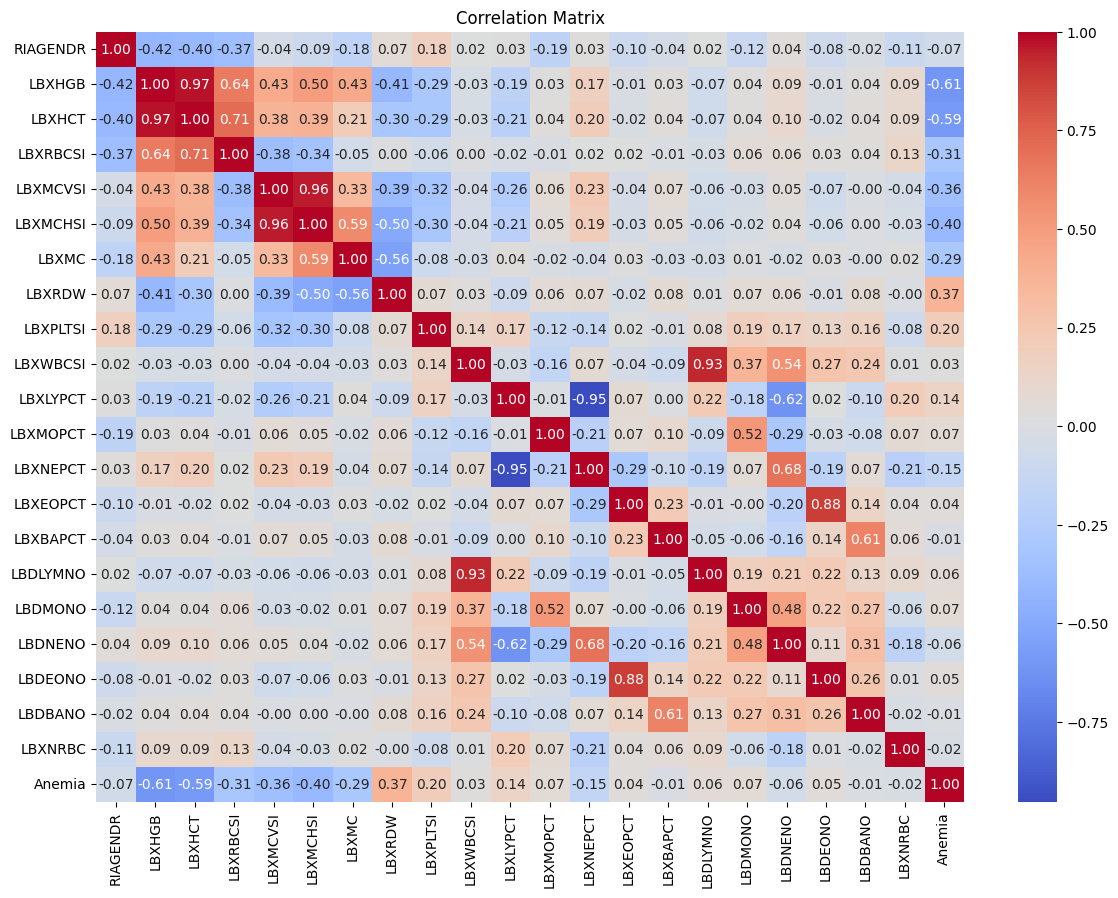

In [19]:
# Correlation heatmap
plt.figure(figsize=(14,10))
sns.heatmap(df.drop('SEQN', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


Logistic regression for animea detection

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Load your cleaned dataset
df = pd.read_csv('../data/nhanes_cleaned.csv')


# Step 2: Drop redundant highly correlated columns
drop_cols = ['LBXHCT', 'LBXMCHSI', 'LBXLYPCT']
df.drop(columns=drop_cols, inplace=True)

# Step 3: Split and scale data
X = df.drop(columns=['Anemia'])
y = df['Anemia']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 4: Train logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# Step 5: Evaluate
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Confusion Matrix:
 [[1277    1]
 [   5  221]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1278
           1       1.00      0.98      0.99       226

    accuracy                           1.00      1504
   macro avg       1.00      0.99      0.99      1504
weighted avg       1.00      1.00      1.00      1504



Save the model

In [21]:
import os

# Create the models directory if it doesn't exist
os.makedirs('../models', exist_ok=True)


In [22]:
import joblib
import os

# Ensure the directory exists
os.makedirs('../models', exist_ok=True)

# Save the model and scaler
joblib.dump(model, '../models/logistic_anemia.pkl')
joblib.dump(scaler, '../models/anemia_scaler.pkl')

print("Model and scaler saved successfully.")

joblib.dump(list(X.columns), '../models/anemia_features.pkl')


Model and scaler saved successfully.


['../models/anemia_features.pkl']

In [23]:
import joblib
import pandas as pd

# Load model and scaler
model = joblib.load('../models/logistic_anemia.pkl')
scaler = joblib.load('../models/anemia_scaler.pkl')

# Load dataset and select sample
df = pd.read_csv('../data/nhanes_cleaned.csv')

# Drop target and redundant columns (same as training)
drop_cols = ['Anemia', 'LBXHCT', 'LBXMCHSI', 'LBXLYPCT']
X_sample = df.drop(columns=drop_cols).iloc[[0]]  # Keep as 2D for transform

# Scale
X_scaled = scaler.transform(X_sample)

# Predict
prediction = model.predict(X_scaled)
print("Predicted anemia status:", "Anemic" if prediction[0] == 1 else "Not Anemic")


Predicted anemia status: Not Anemic


Diabaties risk prediction (Random Forest)

In [24]:
import pandas as pd


In [25]:
# Step 1: Reload merged full dataset
df = combined_df.copy()  # Or reload from saved full file if you have one

In [26]:
combined_df.to_csv("../data/nhanes_full.csv", index=False)


In [27]:
df = pd.read_csv("../data/nhanes_full.csv")


In [28]:
print('LBXGLU' in df.columns)
print('LBXGH' in df.columns)


True
True


LBXGLU = glucose, LBXGH = HbA1c exist.

In [29]:
selected_cols = ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'BMXBMI', 'BPXSY1', 'BPXDI1', 'LBDHDL', 'LBXTC']
available = [col for col in selected_cols if col in combined_df.columns]
print("Available features:", available)


Available features: ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'BMXBMI', 'BPXSY1', 'BPXDI1', 'LBXTC']


selected_cols: gender, age, BMI, blood pressure, cholesterol, etc.

In [30]:
# %% Imports
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import joblib

# %% Step 1: Load Data
df = pd.read_csv("../data/nhanes_full.csv")

# %% Step 2: Create Diabetes Labels
df_diabetes = df[['SEQN', 'LBXGLU', 'LBXGH']].dropna()
df_diabetes['Diabetes'] = ((df_diabetes['LBXGLU'] >= 126) | (df_diabetes['LBXGH'] >= 6.5)).astype(int)

# %% Step 3: Select Features
selected_cols = ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'BMXBMI', 'BPXSY1', 'BPXDI1', 'LBDHDL', 'LBXTC']
available = [col for col in selected_cols if col in df.columns]

# %% Step 4: Merge and Clean
df_model = pd.merge(df_diabetes, df[available], on='SEQN', how='left')
df_model.dropna(inplace=True)

# %% Step 5: Prepare X and y
X = df_model.drop(columns=['SEQN', 'Diabetes', 'LBXGLU', 'LBXGH'])
y = df_model['Diabetes']

# %% Step 6: Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# %% Step 7: Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# %% Step 8: Train Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

# %% Step 9: Evaluate
y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

# %% Step 10: Save Model and Scaler
os.makedirs('../models', exist_ok=True)
joblib.dump(model, '../models/diabetes_model.pkl')
joblib.dump(scaler, '../models/diabetes_scaler.pkl')
print("✅ Model and scaler saved.")
joblib.dump(list(X.columns), '../models/diabetes_features.pkl')



              precision    recall  f1-score   support

           0       0.85      0.96      0.90       414
           1       0.40      0.15      0.21        82

    accuracy                           0.82       496
   macro avg       0.62      0.55      0.56       496
weighted avg       0.78      0.82      0.79       496

✅ Model and scaler saved.


['../models/diabetes_features.pkl']

In [31]:
import joblib
import pandas as pd

# Load saved model and scaler
model = joblib.load('../models/diabetes_model.pkl')
scaler = joblib.load('../models/diabetes_scaler.pkl')

# Example user input
input_data = {
    'RIAGENDR': 1,
    'RIDAGEYR': 55,
    'BMXBMI': 28.5,
    'BPXSY1': 135,
    'BPXDI1': 85,
    'LBDHDL': 40,
    'LBXTC': 210
}

# Convert to DataFrame
input_df = pd.DataFrame([input_data])

# Match training feature order
input_df = input_df[scaler.feature_names_in_]

# Scale input
input_scaled = scaler.transform(input_df)

# Predict
prediction = model.predict(input_scaled)[0]
print("Diabetes Risk:", "Yes" if prediction else "No")


Diabetes Risk: No


In [32]:
print(input_df.shape)
print(input_df.head())


(1, 6)
   RIAGENDR  RIDAGEYR  BMXBMI  BPXSY1  BPXDI1  LBXTC
0         1        55    28.5     135      85    210


Hyper Tension detection

In [33]:
print(df.columns.tolist())


['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMQADFC', 'DMDBORN4', 'DMDCITZN', 'DMDYRSUS', 'DMDEDUC3', 'DMDEDUC2', 'DMDMARTL', 'RIDEXPRG', 'SIALANG', 'SIAPROXY', 'SIAINTRP', 'FIALANG', 'FIAPROXY', 'FIAINTRP', 'MIALANG', 'MIAPROXY', 'MIAINTRP', 'AIALANGA', 'DMDHHSIZ', 'DMDFMSIZ', 'DMDHHSZA', 'DMDHHSZB', 'DMDHHSZE', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA', 'INDHHIN2', 'INDFMIN2', 'INDFMPIR', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP', 'PEASCCT1', 'BPXCHR', 'BPAARM', 'BPACSZ', 'BPXPLS', 'BPXPULS', 'BPXPTY', 'BPXML1', 'BPXSY1', 'BPXDI1', 'BPAEN1', 'BPXSY2', 'BPXDI2', 'BPAEN2', 'BPXSY3', 'BPXDI3', 'BPAEN3', 'BPXSY4', 'BPXDI4', 'BPAEN4', 'WTDRD1_x', 'WTDR2D_x', 'DR1DRSTZ', 'DR1E

In [34]:
import pandas as pd
import pyreadstat
from pathlib import Path

# Load only what's necessary
data_path = Path('../data')

# Load BPX (Blood Pressure)
bpx, _ = pyreadstat.read_xport(data_path / 'BPX_J.XPT')
bpx = bpx[['SEQN', 'BPXSY1', 'BPXDI1']]

# Drop rows with missing blood pressure values
bpx = bpx.dropna(subset=['BPXSY1', 'BPXDI1'])

# Define Hypertension (130/80 or above)
bpx['Hypertension'] = ((bpx['BPXSY1'] >= 130) | (bpx['BPXDI1'] >= 80)).astype(int)

# Final dataset for this model
df = bpx.copy()
print(df.head())
print("✅ Hypertension labels ready. Shape:", df.shape)


      SEQN  BPXSY1  BPXDI1  Hypertension
3  93706.0   112.0    74.0             0
4  93707.0   128.0    38.0             0
6  93709.0   120.0    66.0             0
8  93711.0   108.0    68.0             0
9  93712.0   112.0    68.0             0
✅ Hypertension labels ready. Shape: (6302, 4)


In [35]:
# Load the cleaned lab dataset
lab_data = pd.read_csv('../data/nhanes_cleaned.csv')

# Merge with hypertension-labeled DataFrame
df_full = pd.merge(df, lab_data, on='SEQN', how='inner')

# Drop rows with any missing values
df_full = df_full.dropna()

# Show final shape and check class balance
print("✅ Merged dataset shape:", df_full.shape)
print(df_full['Hypertension'].value_counts())


✅ Merged dataset shape: (5900, 26)
Hypertension
0    3710
1    2190
Name: count, dtype: int64


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import cross_val_score
import joblib
import pandas as pd

# Features and label
X = df_full.drop(columns=['SEQN', 'Hypertension'])
y = df_full['Hypertension']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and fit the scaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaler
joblib.dump(scaler, '../models/hypertension_scaler.pkl')
print("✅ Hypertension scaler saved.")

# Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

# Save the model
joblib.dump(model, '../models/hypertension_model.pkl')
print("✅ Hypertension model saved.")
joblib.dump(list(X.columns), '../models/hypertension_features.pkl')


# Predict
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print(classification_report(y_test, y_pred))
print("AUC-ROC Score:", roc_auc_score(y_test, y_prob))

# Cross-validation (on entire scaled dataset)
X_scaled = scaler.transform(X)
scores = cross_val_score(model, X_scaled, y, cv=5, scoring='accuracy')
print("Cross-validation scores:", scores)
print("Mean CV Accuracy:", scores.mean())


✅ Hypertension scaler saved.
✅ Hypertension model saved.
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       760
           1       1.00      1.00      1.00       420

    accuracy                           1.00      1180
   macro avg       1.00      1.00      1.00      1180
weighted avg       1.00      1.00      1.00      1180

AUC-ROC Score: 1.0
Cross-validation scores: [1. 1. 1. 1. 1.]
Mean CV Accuracy: 1.0


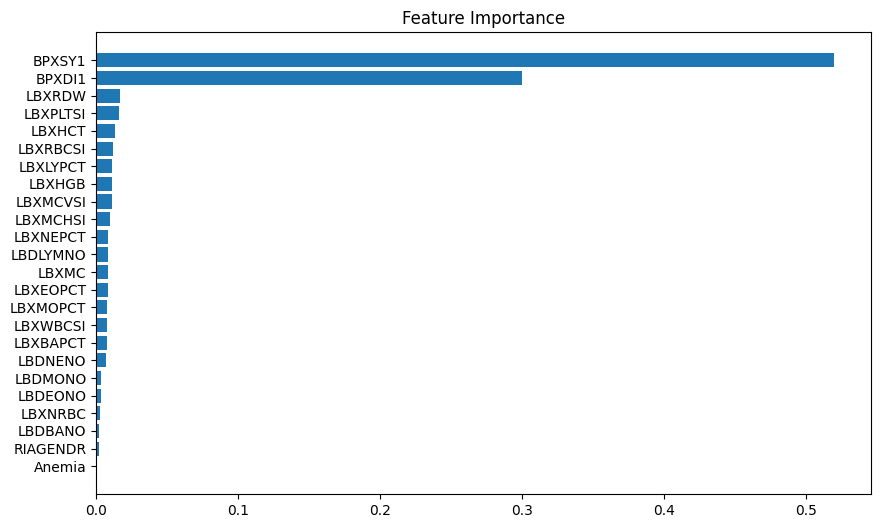

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

importances = model.feature_importances_
feature_names = X.columns
feat_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_importance_df = feat_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feat_importance_df['Feature'], feat_importance_df['Importance'])
plt.gca().invert_yaxis()
plt.title("Feature Importance")
plt.show()


In [38]:
import joblib
import pandas as pd

# Load model and scaler
model = joblib.load('../models/hypertension_model.pkl')
scaler = joblib.load('../models/hypertension_scaler.pkl')

# Get feature names used during training
feature_names = X.columns.tolist()

# Example input (make sure this has EXACTLY len(feature_names) values)
input_data = [[25.0, 1, 20.0, 2.1, 13.0, 1.2, 190.0, 70.0, 2.3,
               145.0, 88.0, 1, 1.0, 0.6, 120.0, 4.1, 0.9,
               1800.0, 1300.0, 30.0, 55.0, 4200.0, 1600.0, 3100.0]]  # <-- now 24 values


# Check input validity
print("Number of features expected:", len(feature_names))
print("Number of features given:", len(input_data[0]))

# Construct input DataFrame
input_df = pd.DataFrame(input_data, columns=feature_names)

# Scale and predict
input_scaled = scaler.transform(input_df)
prediction = model.predict(input_scaled)[0]
probability = model.predict_proba(input_scaled)[0][1]

print("Prediction (0 = No HTN, 1 = HTN):", prediction)
print("Probability of Hypertension:", round(probability, 2))


Number of features expected: 24
Number of features given: 24
Prediction (0 = No HTN, 1 = HTN): 0
Probability of Hypertension: 0.23


obesity prediction

In [39]:
print(df.columns)


Index(['SEQN', 'BPXSY1', 'BPXDI1', 'Hypertension'], dtype='object')


In [40]:
import pandas as pd
import os

# Load your cleaned dataset (already done, df)
# df = pd.read_csv('../data/nhanes_cleaned.csv')

# Load BMX_J.XPT (body measurements)
bmx_df = pd.read_sas('../data/BMX_J.XPT')

# Check columns in BMX_J.XPT
print(bmx_df.columns)

# BMXWT = weight in kilograms
# BMXHT = height in centimeters
# SEQN = unique participant ID (common key)

# Merge on SEQN (participant ID)
df = df.merge(bmx_df[['SEQN', 'BMXWT', 'BMXHT']], on='SEQN', how='left')

# Calculate BMI
df['BMXBMI'] = df['BMXWT'] / ((df['BMXHT'] / 100) ** 2)

# Check for nulls or missing BMI values
print(df[['BMXWT', 'BMXHT', 'BMXBMI']].isnull().sum())

# Now you can proceed to create Obese target
df['Obese'] = (df['BMXBMI'] >= 30).astype(int)

# Confirm obesity distribution
print(df['Obese'].value_counts())


Index(['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD',
       'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMXLEG', 'BMILEG', 'BMXARML',
       'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP',
       'BMIHIP'],
      dtype='object')
BMXWT     62
BMXHT     64
BMXBMI    72
dtype: int64
Obese
0    4196
1    2106
Name: count, dtype: int64


In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Load cleaned NHANES dataset
df = pd.read_csv('../data/nhanes_cleaned.csv')

# Load BMX_J.XPT to get height and weight
bmx_df = pd.read_sas('../data/BMX_J.XPT')

# Merge height and weight into main df using SEQN
df = df.merge(bmx_df[['SEQN', 'BMXWT', 'BMXHT']], on='SEQN', how='left')

# Calculate BMI
df['BMXBMI'] = df['BMXWT'] / ((df['BMXHT'] / 100) ** 2)

# Drop rows with missing BMI values
df = df.dropna(subset=['BMXBMI'])

# Create Obese target column
df['Obese'] = (df['BMXBMI'] >= 30).astype(int)

# Define features and target
X = df.drop(columns=['Obese', 'BMXBMI'])
y = df['Obese']

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Handle missing values
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Train the model
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_scaled, y_train)

# Predict
y_pred = rf_clf.predict(X_test_scaled)
y_proba = rf_clf.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("Classification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Show predictions
results_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Probability_Obese': y_proba
}).reset_index(drop=True)

print("\nSample Predictions:")
print(results_df.head())


Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97       998
           1       0.96      0.92      0.94       458

    accuracy                           0.96      1456
   macro avg       0.96      0.95      0.96      1456
weighted avg       0.96      0.96      0.96      1456

ROC-AUC Score: 0.9952897060496538
Confusion Matrix:
 [[980  18]
 [ 35 423]]

Sample Predictions:
   Actual  Predicted  Probability_Obese
0       0          0               0.03
1       0          0               0.00
2       0          0               0.11
3       0          0               0.03
4       1          1               0.92


In [42]:
import numpy as np
import pandas as pd

# List of feature columns used for training (get this from your training data)
feature_cols = X.columns.tolist()

# Your new input data as a dict, only partially filled
new_data_partial = {
    'BPXSY1': 120,
    'BPXDI1': 80,
    'RIAGENDR': 1,
    # ... add known features here
}

# Create a full input row with all features, fill missing with np.nan
new_data_full = {col: new_data_partial.get(col, np.nan) for col in feature_cols}

# Convert to DataFrame (1 row)
new_df = pd.DataFrame([new_data_full], columns=feature_cols)

# Impute missing values (using fitted imputer)
new_imputed = imputer.transform(new_df)

# Scale features (using fitted scaler)
new_scaled = scaler.transform(new_imputed)

# Predict class and probability
predicted_class = rf_clf.predict(new_scaled)[0]
predicted_prob = rf_clf.predict_proba(new_scaled)[0,1]

print(f"Predicted Class: {predicted_class} ({'Obese' if predicted_class==1 else 'Not Obese'})")
print(f"Probability of Obesity: {predicted_prob:.2f}")


Predicted Class: 0 (Not Obese)
Probability of Obesity: 0.00


In [43]:
joblib.dump(list(X.columns), '../models/obesity_features.pkl')


['../models/obesity_features.pkl']

Metabolic syndrome

In [44]:
import pandas as pd

# Load merged NHANES dataset
df = pd.read_csv('../data/nhanes_full.csv')

# Select necessary columns
required_cols = [
    'RIAGENDR',    # Gender
    'BMXWAIST',    # Waist
    'LBXTR',       # Triglycerides
    'LBDHDD',      # HDL Cholesterol
    'BPXSY1',      # Systolic BP
    'BPXDI1',      # Diastolic BP
    'LBXGLU'       # Glucose
]

df_meta = df[required_cols].dropna()
print("Filtered shape:", df_meta.shape)
df_meta.head()


Filtered shape: (2429, 7)


,RIAGENDR,BMXWAIST,LBXTR,LBDHDD,BPXSY1,BPXDI1,LBXGLU
8,1.0,86.6,48.0,72.0,108.0,68.0,107.0
14,1.0,86.2,102.0,53.0,116.0,62.0,91.0
15,1.0,77.5,46.0,63.0,128.0,88.0,89.0
16,2.0,86.0,80.0,46.0,102.0,62.0,86.0
18,2.0,113.2,79.0,45.0,132.0,68.0,104.0


In [45]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import pickle
import pandas as pd


# Load full dataset
df = pd.read_csv('../data/nhanes_full.csv')

# Select and drop missing
cols = ['RIAGENDR', 'BMXWAIST', 'LBXTR', 'LBDHDD', 'BPXSY1', 'BPXDI1', 'LBXGLU']
df_meta = df[cols].dropna()

# Create label
def assign_metabolic_syndrome(row):
    count = 0
    if (row['RIAGENDR'] == 1 and row['BMXWAIST'] > 102) or \
       (row['RIAGENDR'] == 2 and row['BMXWAIST'] > 88):
        count += 1
    if row['LBXTR'] >= 150:
        count += 1
    if (row['RIAGENDR'] == 1 and row['LBDHDD'] < 40) or \
       (row['RIAGENDR'] == 2 and row['LBDHDD'] < 50):
        count += 1
    if row['BPXSY1'] >= 130 or row['BPXDI1'] >= 85:
        count += 1
    if row['LBXGLU'] >= 100:
        count += 1
    return 1 if count >= 3 else 0

df_meta['MetabolicSyndrome'] = df_meta.apply(assign_metabolic_syndrome, axis=1)

# Features and target
X = df_meta.drop(columns=['MetabolicSyndrome'])
y = df_meta['MetabolicSyndrome']

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, stratify=y, test_size=0.2, random_state=42)

# Model
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

# Save model and scaler
with open('../models/metabolic_model.pkl', 'wb') as f:
    pickle.dump(clf, f)
with open('../models/metabolic_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
joblib.dump(list(X.columns), '../models/metabolic_features.pkl')


              precision    recall  f1-score   support

           0       0.95      0.98      0.97       322
           1       0.97      0.91      0.94       164

    accuracy                           0.96       486
   macro avg       0.96      0.95      0.95       486
weighted avg       0.96      0.96      0.96       486



['../models/metabolic_features.pkl']

In [46]:
import numpy as np
import pickle

# Load model and scaler
with open('../models/metabolic_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('../models/metabolic_scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

# Example input data (same columns, same order)
# Columns: ['RIAGENDR', 'BMXWAIST', 'LBXTR', 'LBDHDD', 'BPXSY1', 'BPXDI1', 'LBXGLU']
sample_data = [
    [1, 86.6, 48.0, 72.0, 108.0, 68.0, 107.0],  # Should return 1 (likely MetS)
    [1, 86.2, 102.0, 53.0, 116.0, 62.0, 91.0],  # Could return 1
    [1, 77.5, 46.0, 63.0, 128.0, 88.0, 89.0],   # Could return 0
    [2, 86.0, 80.0, 46.0, 102.0, 62.0, 86.0],   # Likely 0
    [2, 113.2, 79.0, 45.0, 132.0, 68.0, 104.0]  # Likely 1
]

# Scale
sample_scaled = scaler.transform(sample_data)

# Predict
predictions = model.predict(sample_scaled)
print(predictions)


[0 0 0 0 1]


c:\Users\HP\ai-health-assistant\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Nutrient deficiency risk model

In [47]:
import pandas as pd

df = pd.read_sas('../data/DR1TOT_J.XPT')
print(df.columns.tolist())


['SEQN', 'WTDRD1', 'WTDR2D', 'DR1DRSTZ', 'DR1EXMER', 'DRABF', 'DRDINT', 'DR1DBIH', 'DR1DAY', 'DR1LANG', 'DR1MRESP', 'DR1HELP', 'DBQ095Z', 'DBD100', 'DRQSPREP', 'DR1STY', 'DR1SKY', 'DRQSDIET', 'DRQSDT1', 'DRQSDT2', 'DRQSDT3', 'DRQSDT4', 'DRQSDT5', 'DRQSDT6', 'DRQSDT7', 'DRQSDT8', 'DRQSDT9', 'DRQSDT10', 'DRQSDT11', 'DRQSDT12', 'DRQSDT91', 'DR1TNUMF', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TSUGR', 'DR1TFIBE', 'DR1TTFAT', 'DR1TSFAT', 'DR1TMFAT', 'DR1TPFAT', 'DR1TCHOL', 'DR1TATOC', 'DR1TATOA', 'DR1TRET', 'DR1TVARA', 'DR1TACAR', 'DR1TBCAR', 'DR1TCRYP', 'DR1TLYCO', 'DR1TLZ', 'DR1TVB1', 'DR1TVB2', 'DR1TNIAC', 'DR1TVB6', 'DR1TFOLA', 'DR1TFA', 'DR1TFF', 'DR1TFDFE', 'DR1TCHL', 'DR1TVB12', 'DR1TB12A', 'DR1TVC', 'DR1TVD', 'DR1TVK', 'DR1TCALC', 'DR1TPHOS', 'DR1TMAGN', 'DR1TIRON', 'DR1TZINC', 'DR1TCOPP', 'DR1TSODI', 'DR1TPOTA', 'DR1TSELE', 'DR1TCAFF', 'DR1TTHEO', 'DR1TALCO', 'DR1TMOIS', 'DR1TS040', 'DR1TS060', 'DR1TS080', 'DR1TS100', 'DR1TS120', 'DR1TS140', 'DR1TS160', 'DR1TS180', 'DR1TM161', 'DR1TM

In [48]:
import pandas as pd
import pyreadstat

df_dr1tot, meta1 = pyreadstat.read_xport('DR1TOT_J.xpt')
df_dr2tot, meta2 = pyreadstat.read_xport('DR2TOT_J.xpt')
df_demo, meta_demo = pyreadstat.read_xport('DEMO_J.xpt')
df_bmx, meta_bmx = pyreadstat.read_xport('BMX_J.xpt')


# Merge Day 1 and Day 2 intake data on SEQN
df_nutrient = pd.merge(df_dr1tot, df_dr2tot, on='SEQN', suffixes=('_DR1', '_DR2'))

# Merge with demographics and body measures
df_full = df_nutrient.merge(df_demo, on='SEQN').merge(df_bmx, on='SEQN')

print(df_full.shape)
print(df_full.columns)

# Now df_full has nutrient intake + demographics + body measures


(8704, 317)
Index(['SEQN', 'WTDRD1_DR1', 'WTDR2D_DR1', 'DR1DRSTZ', 'DR1EXMER', 'DRABF_DR1',
       'DRDINT_DR1', 'DR1DBIH', 'DR1DAY', 'DR1LANG',
       ...
       'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC',
       'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP'],
      dtype='object', length=317)


In [49]:
# Average iron intake from Day 1 and Day 2
df_full['Iron_Intake'] = df_full[['DR1TIRON', 'DR2TIRON']].mean(axis=1)

# Define deficiency risk target (1 = deficient, 0 = sufficient)
df_full['NutrientDeficiencyRisk'] = (df_full['Iron_Intake'] < 8).astype(int)

# Define feature columns (nutrient intake + demographic)
feature_cols = [
    'DR1TKCAL', 'DR2TKCAL',   # Energy intake Day1 & Day2
    'DR1TPROT', 'DR2TPROT',   # Protein intake
    'DR1TCARB', 'DR2TCARB',   # Carbs
    'DR1TFIBE', 'DR2TFIBE',   # Fiber
    'DR1TCAFF', 'DR2TCAFF',   # Caffeine
    'RIDAGEYR', 'RIAGENDR'    # Age, Gender
]

# Filter features present in dataframe
feature_cols = [col for col in feature_cols if col in df_full.columns]

X = df_full[feature_cols]
y = df_full['NutrientDeficiencyRisk']

# Drop missing values in features and target
X = X.dropna()
y = y.loc[X.index]

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Predict and evaluate
from sklearn.metrics import classification_report, confusion_matrix
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.89      0.96      0.93      1051
           1       0.77      0.51      0.62       248

    accuracy                           0.88      1299
   macro avg       0.83      0.74      0.77      1299
weighted avg       0.87      0.88      0.87      1299

[[1014   37]
 [ 121  127]]


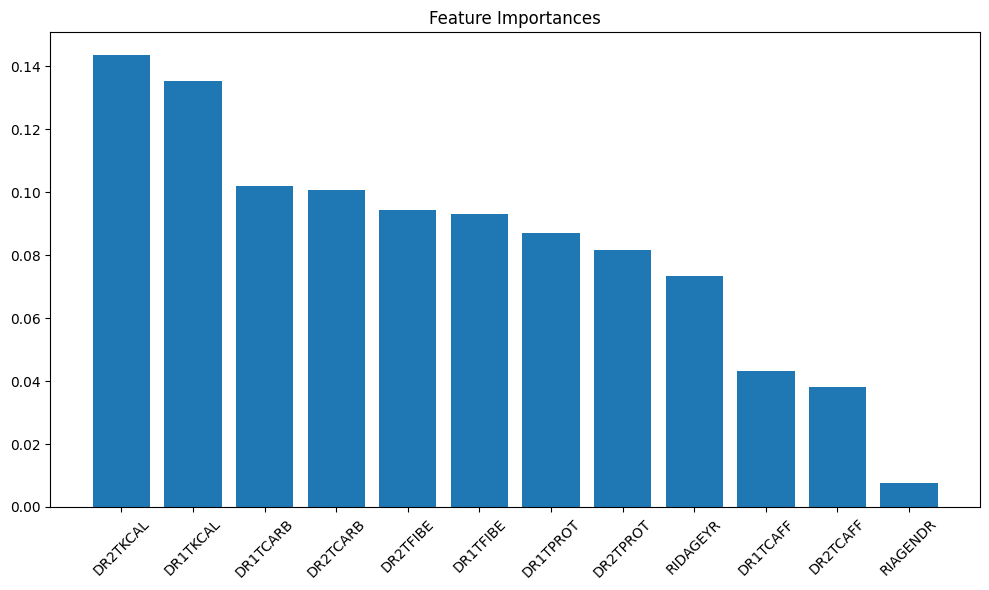

In [50]:
import matplotlib.pyplot as plt

importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Feature Importances")
plt.bar(range(len(importances)), importances[indices], align="center")
plt.xticks(range(len(importances)), [feature_cols[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()


In [51]:
import joblib

joblib.dump(clf, 'nutrient_deficiency_rf_model.pkl')
joblib.dump(feature_cols, 'nutrient_feature_columns.pkl')
joblib.dump(list(X.columns), '../models/nutrient_features.pkl')



['../models/nutrient_features.pkl']

In [52]:
def predict_nutrient_deficiency(input_data, model, feature_list):
    import pandas as pd
    df = pd.DataFrame([input_data])
    df = df[feature_list]  # Keep only features model expects
    prediction = model.predict(df)
    return prediction[0]


In [53]:
# Average intake per nutrient
df_full['Iron_Intake'] = df_full[['DR1TIRON', 'DR2TIRON']].mean(axis=1)
df_full['VitaminD_Intake'] = df_full[['DR1TVD', 'DR2TVD']].mean(axis=1)
df_full['Calcium_Intake'] = df_full[['DR1TCALC', 'DR2TCALC']].mean(axis=1)
df_full['B12_Intake'] = df_full[['DR1TB12A', 'DR2TB12A']].mean(axis=1)

# Define deficiency flags (1 = deficient, 0 = sufficient)
df_full['Iron_Deficiency'] = (df_full['Iron_Intake'] < 8).astype(int)
df_full['VitaminD_Deficiency'] = (df_full['VitaminD_Intake'] < 20).astype(int)
df_full['Calcium_Deficiency'] = (df_full['Calcium_Intake'] < 1000).astype(int)
df_full['B12_Deficiency'] = (df_full['B12_Intake'] < 300).astype(int)


In [54]:
# Features to use - extend with nutrients or demographics as needed
feature_cols = [
    'DR1TKCAL', 'DR2TKCAL',   # Calories
    'DR1TPROT', 'DR2TPROT',   # Protein
    'DR1TCARB', 'DR2TCARB',   # Carbs
    'DR1TFIBE', 'DR2TFIBE',   # Fiber
    'DR1TCAFF', 'DR2TCAFF',   # Caffeine
    'RIDAGEYR', 'RIAGENDR'    # Age, Gender
]

# Filter existing features
feature_cols = [c for c in feature_cols if c in df_full.columns]

X = df_full[feature_cols].dropna()

# Targets for multi-label classification
y = df_full.loc[X.index, ['Iron_Deficiency', 'VitaminD_Deficiency', 'Calcium_Deficiency', 'B12_Deficiency']]


In [55]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base_clf = RandomForestClassifier(random_state=42)
multi_clf = MultiOutputClassifier(base_clf)

multi_clf.fit(X_train, y_train)

y_pred = multi_clf.predict(X_test)

# Print classification reports for each nutrient
for i, nutrient in enumerate(y.columns):
    print(f"Classification report for {nutrient}:\n")
    print(classification_report(y_test.iloc[:, i], y_pred[:, i]))


Classification report for Iron_Deficiency:

              precision    recall  f1-score   support

           0       0.89      0.96      0.93      1051
           1       0.77      0.51      0.62       248

    accuracy                           0.88      1299
   macro avg       0.83      0.74      0.77      1299
weighted avg       0.87      0.88      0.87      1299

Classification report for VitaminD_Deficiency:

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        14
           1       0.99      1.00      0.99      1285

    accuracy                           0.99      1299
   macro avg       0.49      0.50      0.50      1299
weighted avg       0.98      0.99      0.98      1299

Classification report for Calcium_Deficiency:

              precision    recall  f1-score   support

           0       0.63      0.60      0.61       397
           1       0.83      0.85      0.84       902

    accuracy                           0.77

c:\Users\HP\ai-health-assistant\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\HP\ai-health-assistant\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\HP\ai-health-assistant\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [56]:
import joblib
from sklearn.impute import SimpleImputer

joblib.dump(multi_clf, '../models/multi_nutrient_deficiency_model.pkl')
joblib.dump(feature_cols, '../models/nutrient_feature_columns.pkl')

imputer = SimpleImputer(strategy='mean')
imputer.fit(X_train[feature_cols])  # Use feature_cols, not nutrient_features
joblib.dump(imputer, '../models/nutrient_imputer.pkl')

['../models/nutrient_imputer.pkl']

In [57]:
import pandas as pd

def predict_nutrient_deficiency(input_data, model, feature_list):
    if isinstance(input_data, dict):
        df = pd.DataFrame([input_data])
    else:
        df = input_data

    df = df[feature_list]
    predictions = model.predict(df)
    
    # Map predictions to nutrient names
    nutrient_names = ['Iron_Deficiency', 'VitaminD_Deficiency', 'Calcium_Deficiency', 'B12_Deficiency']
    result = {nutrient: bool(pred) for nutrient, pred in zip(nutrient_names, predictions[0])}
    return result


In [58]:
# Load model and features
multi_clf = joblib.load('../models/multi_nutrient_deficiency_model.pkl')
feature_cols = joblib.load('../models/nutrient_feature_columns.pkl')

# Sample user input
user_input = {
    'DR1TKCAL': 1800,
    'DR2TKCAL': 1900,
    'DR1TPROT': 70,
    'DR2TPROT': 65,
    'DR1TCARB': 220,
    'DR2TCARB': 210,
    'DR1TFIBE': 18,
    'DR2TFIBE': 20,
    'DR1TCAFF': 50,
    'DR2TCAFF': 60,
    'RIDAGEYR': 35,
    'RIAGENDR': 1  # 1=Male, 2=Female
}

prediction = predict_nutrient_deficiency(user_input, multi_clf, feature_cols)
print("Nutrient Deficiency Risk Prediction:", prediction)


Nutrient Deficiency Risk Prediction: {'Iron_Deficiency': False, 'VitaminD_Deficiency': True, 'Calcium_Deficiency': True, 'B12_Deficiency': True}


In [59]:
import os

model_folder = '../models'
model_files = [f for f in os.listdir(model_folder) if f.endswith('.pkl') or f.endswith('.joblib')]

print("Saved model files:")
for file in model_files:
    print(file)


Saved model files:
anemia_features.pkl
anemia_model.pkl
anemia_scaler.pkl
diabetes_features.pkl
diabetes_model.pkl
diabetes_scaler.pkl
hypertension_features.pkl
hypertension_model.pkl
hypertension_scaler.pkl
logistic_anemia.pkl
metabolic_features.pkl
metabolic_model.pkl
metabolic_scaler.pkl
multi_nutrient_deficiency_model.pkl
nutrient_features.pkl
nutrient_feature_columns.pkl
nutrient_imputer.pkl
nutrient_model.pkl
obesity_features.pkl
obesity_imputer.pkl
obesity_model.pkl
obesity_scaler.pkl
stress_label_encoder.pkl


outline unified interace function

In [60]:
import os
import pandas as pd

# Directory containing all saved model and feature files
model_folder = '../models'

# List all files in the model directory
model_files = [f for f in os.listdir(model_folder) if f.endswith('.pkl') or f.endswith('.joblib')]

# Create a DataFrame to organize file info
file_info = []
for file in sorted(model_files):
    # Infer type from filename
    if 'model' in file:
        file_type = 'Model'
    elif 'scaler' in file or 'imputer' in file:
        file_type = 'Scaler/Imputer'
    elif 'feature' in file:
        file_type = 'Feature List'
    else:
        file_type = 'Other'
    file_info.append({'File Name': file, 'Type': file_type})

df_files = pd.DataFrame(file_info)
print(df_files)

                              File Name            Type
0                   anemia_features.pkl    Feature List
1                      anemia_model.pkl           Model
2                     anemia_scaler.pkl  Scaler/Imputer
3                 diabetes_features.pkl    Feature List
4                    diabetes_model.pkl           Model
5                   diabetes_scaler.pkl  Scaler/Imputer
6             hypertension_features.pkl    Feature List
7                hypertension_model.pkl           Model
8               hypertension_scaler.pkl  Scaler/Imputer
9                   logistic_anemia.pkl           Other
10               metabolic_features.pkl    Feature List
11                  metabolic_model.pkl           Model
12                 metabolic_scaler.pkl  Scaler/Imputer
13  multi_nutrient_deficiency_model.pkl           Model
14         nutrient_feature_columns.pkl    Feature List
15                nutrient_features.pkl    Feature List
16                 nutrient_imputer.pkl  Scaler/

In [61]:
# Check for inconsistencies between model files and expected naming conventions

expected_keywords = [
    'anemia', 'diabetes', 'hypertension', 'obesity', 'metabolic', 'nutrient'
]

# List all files in the model directory
model_files_set = set(model_files)

# Check for files that do not match any expected keyword
wrong_files = [
    f for f in model_files
    if not any(keyword in f for keyword in expected_keywords)
]

print("Files with potentially wrong or unexpected names:")
for f in wrong_files:
    print(f)

Files with potentially wrong or unexpected names:
stress_label_encoder.pkl


In [62]:
import joblib
import pickle
import os

model_folder = '../models'
files_to_check = [
    'anemia_features.pkl',
    'anemia_scaler.pkl',
    'diabetes_features.pkl',
    'diabetes_model.pkl',
    'diabetes_scaler.pkl',
    'hypertension_features.pkl',
    'hypertension_model.pkl',
    'hypertension_scaler.pkl',
    'imputer.joblib',
    'logistic_anemia.pkl',
    'metabolic_features.pkl',
    'metabolic_model.pkl',
    'metabolic_scaler.pkl',
    'multi_nutrient_deficiency_model.pkl',
    'nutrient_features.pkl',
    'nutrient_feature_columns.pkl',
    'nutrient_imputer.pkl',
    'obese_features.pkl',
    'obesity_features.pkl',
    'obesity_scaler.joblib',
    'rf_obesity_model.joblib'
]

def try_load(path):
    try:
        if path.endswith('.pkl') or path.endswith('.joblib'):
            # Try joblib first, fallback to pickle
            try:
                obj = joblib.load(path)
                return type(obj)
            except Exception:
                with open(path, 'rb') as f:
                    obj = pickle.load(f)
                return type(obj)
        else:
            return "Unknown file type"
    except Exception as e:
        return f"Error: {e}"

file_contents = {}
for fname in files_to_check:
    fpath = os.path.join(model_folder, fname)
    file_contents[fname] = try_load(fpath)

for fname, ftype in file_contents.items():
    print(f"{fname}: {ftype}")

anemia_features.pkl: <class 'list'>
anemia_scaler.pkl: <class 'sklearn.preprocessing._data.StandardScaler'>
diabetes_features.pkl: <class 'list'>
diabetes_model.pkl: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
diabetes_scaler.pkl: <class 'sklearn.preprocessing._data.StandardScaler'>
hypertension_features.pkl: <class 'list'>
hypertension_model.pkl: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
hypertension_scaler.pkl: <class 'sklearn.preprocessing._data.StandardScaler'>
imputer.joblib: Error: [Errno 2] No such file or directory: '../models\\imputer.joblib'
logistic_anemia.pkl: <class 'sklearn.linear_model._logistic.LogisticRegression'>
metabolic_features.pkl: <class 'list'>
metabolic_model.pkl: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
metabolic_scaler.pkl: <class 'sklearn.preprocessing._data.StandardScaler'>
multi_nutrient_deficiency_model.pkl: <class 'sklearn.multioutput.MultiOutputClassifier'>
nutrient_features.pkl: <class 'list'>
nutrient_fe

In [63]:
import os
import shutil

# Define mapping from wrong to correct filenames
rename_map = {
    'imputer.joblib': 'obesity_imputer.joblib',
    'obese_features.pkl': 'obesity_features.pkl'
}

model_folder = '../models'

for old_name, new_name in rename_map.items():
    old_path = os.path.join(model_folder, old_name)
    new_path = os.path.join(model_folder, new_name)
    if os.path.exists(old_path):
        # Only rename if the new name does not already exist
        if not os.path.exists(new_path):
            shutil.move(old_path, new_path)
            print(f"Renamed {old_name} -> {new_name}")
        else:
            print(f"Skipped {old_name}: {new_name} already exists.")
    else:
        print(f"File {old_name} not found, skipping.")

File imputer.joblib not found, skipping.
File obese_features.pkl not found, skipping.


In [64]:
import os
from collections import defaultdict

# List all files in the models directory
model_folder = '../models'
model_files = sorted([f for f in os.listdir(model_folder) if f.endswith('.pkl') or f.endswith('.joblib')])

# Group files by their base name (without extension)
file_groups = defaultdict(list)
for f in model_files:
    base = f.replace('.pkl', '').replace('.joblib', '')
    file_groups[base].append(f)

# Print groups with more than one file (potential duplicates)
print("Potential duplicate files:")
for base, files in file_groups.items():
    if len(files) > 1:
        print(f"{base}: {files}")

# Manually decide which files are unnecessary (based on previous context)
# For example, 'obese_features.pkl' is a duplicate of 'obesity_features.pkl'
unnecessary_files = [
    'obese_features.pkl',
    'imputer.joblib'
]

# Delete unnecessary files
for fname in unnecessary_files:
    fpath = os.path.join(model_folder, fname)
    if os.path.exists(fpath):
        os.remove(fpath)
        print(f"Deleted: {fname}")
    else:
        print(f"File not found (already deleted?): {fname}")

Potential duplicate files:
File not found (already deleted?): obese_features.pkl
File not found (already deleted?): imputer.joblib


In [65]:
import os
import shutil

# Define a consistent naming convention for all model-related files
# Example: <task>_<type>.pkl or .joblib (task: anemia, diabetes, hypertension, obesity, metabolic, nutrient)
# type: model, scaler, imputer, features

rename_map = {
    # Anemia
    'logistic_anemia.pkl': 'anemia_model.pkl',
    # Diabetes
    # Already consistent: diabetes_model.pkl, diabetes_scaler.pkl, diabetes_features.pkl
    # Hypertension
    # Already consistent: hypertension_model.pkl, hypertension_scaler.pkl, hypertension_features.pkl
    # Obesity
    'rf_obesity_model.joblib': 'obesity_model.pkl',
    'obesity_scaler.joblib': 'obesity_scaler.pkl',
    'obesity_imputer.joblib': 'obesity_imputer.pkl',
    # Metabolic syndrome
    # Already consistent: metabolic_model.pkl, metabolic_scaler.pkl, metabolic_features.pkl
    # Nutrient deficiency
    'multi_nutrient_deficiency_model.pkl': 'nutrient_model.pkl',
    'nutrient_feature_columns.pkl': 'nutrient_features.pkl',
    # Remove duplicates/old
    'obese_features.pkl': None,
    'imputer.joblib': None,
}

model_folder = '../models'

for old_name, new_name in rename_map.items():
    old_path = os.path.join(model_folder, old_name)
    if new_name is None:
        # Remove file if it exists
        if os.path.exists(old_path):
            os.remove(old_path)
            print(f"Deleted: {old_name}")
    else:
        new_path = os.path.join(model_folder, new_name)
        if os.path.exists(old_path):
            if not os.path.exists(new_path):
                shutil.move(old_path, new_path)
                print(f"Renamed {old_name} -> {new_name}")
            else:
                print(f"Skipped {old_name}: {new_name} already exists.")

Skipped logistic_anemia.pkl: anemia_model.pkl already exists.
Skipped multi_nutrient_deficiency_model.pkl: nutrient_model.pkl already exists.
Skipped nutrient_feature_columns.pkl: nutrient_features.pkl already exists.


In [66]:
import pandas as pd
import numpy as np

# Define df_obese as a DataFrame with the same columns as obesity_features

# Example: create a dummy df_obese with 5 rows of random data for demonstration
df_obese = pd.DataFrame({
    'SEQN': np.arange(1, 6),
    'RIAGENDR': np.random.choice([1, 2], size=5),
    'LBXHGB': np.random.uniform(10, 18, size=5),
    'LBXHCT': np.random.uniform(30, 50, size=5),
    'LBXRBCSI': np.random.uniform(3.5, 6.0, size=5),
    'LBXMCVSI': np.random.uniform(70, 100, size=5),
    'LBXMCHSI': np.random.uniform(20, 35, size=5),
    'LBXMC': np.random.uniform(25, 36, size=5),
    'LBXRDW': np.random.uniform(11, 16, size=5),
    'LBXPLTSI': np.random.uniform(150, 400, size=5),
    'LBXWBCSI': np.random.uniform(4, 11, size=5),
    'LBXLYPCT': np.random.uniform(20, 50, size=5),
    'LBXMOPCT': np.random.uniform(2, 10, size=5),
    'LBXNEPCT': np.random.uniform(40, 70, size=5),
    'LBXEOPCT': np.random.uniform(0.5, 5, size=5),
    'LBXBAPCT': np.random.uniform(0.1, 1, size=5),
    'LBDLYMNO': np.random.uniform(1, 4, size=5),
    'LBDMONO': np.random.uniform(0.2, 1, size=5),
    'LBDNENO': np.random.uniform(2, 7, size=5),
    'LBDEONO': np.random.uniform(0.1, 0.5, size=5),
    'LBDBANO': np.random.uniform(0.1, 0.5, size=5),
    'LBXNRBC': np.random.uniform(0, 0.2, size=5),
    'Anemia': np.random.choice([0, 1], size=5),
    'BMXWT': np.random.uniform(50, 120, size=5),
    'BMXHT': np.random.uniform(150, 200, size=5)
})

In [67]:
test_input = df_obese.iloc[0].to_dict()

In [68]:
import joblib
import pickle
import numpy as np
import pandas as pd

# --- Load all models, scalers, imputers, and feature lists ---
model_dir = '../models'

# Helper to load .pkl or .joblib
def load_obj(fname):
    path = f"{model_dir}/{fname}"
    try:
        return joblib.load(path)
    except Exception:
        with open(path, 'rb') as f:
            return pickle.load(f)

# Loaders for each model
anemia_model = load_obj('anemia_model.pkl')
anemia_scaler = load_obj('anemia_scaler.pkl')
anemia_features = load_obj('anemia_features.pkl')

diabetes_model = load_obj('diabetes_model.pkl')
diabetes_scaler = load_obj('diabetes_scaler.pkl')
diabetes_features = load_obj('diabetes_features.pkl')

hypertension_model = load_obj('hypertension_model.pkl')
hypertension_scaler = load_obj('hypertension_scaler.pkl')
hypertension_features = load_obj('hypertension_features.pkl')

obesity_model = load_obj('obesity_model.pkl')
obesity_scaler = load_obj('obesity_scaler.pkl')
obesity_imputer = load_obj('obesity_imputer.pkl')
obesity_features = load_obj('obesity_features.pkl')

metabolic_model = load_obj('metabolic_model.pkl')
metabolic_scaler = load_obj('metabolic_scaler.pkl')
metabolic_features = load_obj('metabolic_features.pkl')

nutrient_model = load_obj('nutrient_model.pkl')
nutrient_features = load_obj('nutrient_features.pkl')
nutrient_imputer = load_obj('nutrient_imputer.pkl')

# --- Unified prediction function ---
def unified_predict(user_input):
    results = {}

    # Helper to prepare input for a model
    def prepare_input(features, imputer=None, scaler=None):
        row = {f: user_input.get(f, np.nan) for f in features}
        X = pd.DataFrame([row], columns=features)
        if imputer is not None:
            X = pd.DataFrame(imputer.transform(X), columns=features)
        if scaler is not None:
            X = scaler.transform(X)
        return X

    # Anemia
    try:
        X = prepare_input(anemia_features, scaler=anemia_scaler)
        pred = anemia_model.predict(X)[0]
        results['Anemia'] = int(pred)
    except Exception as e:
        results['Anemia'] = None

    # Diabetes
    try:
        X = prepare_input(diabetes_features, scaler=diabetes_scaler)
        pred = diabetes_model.predict(X)[0]
        results['Diabetes'] = int(pred)
    except Exception as e:
        results['Diabetes'] = None

    # Hypertension
    try:
        X = prepare_input(hypertension_features, scaler=hypertension_scaler)
        pred = hypertension_model.predict(X)[0]
        results['Hypertension'] = int(pred)
    except Exception as e:
        results['Hypertension'] = None

    # Obesity
    try:
        X = prepare_input(obesity_features, imputer=obesity_imputer, scaler=obesity_scaler)
        pred = obesity_model.predict(X)[0]
        results['Obesity'] = int(pred)
    except Exception as e:
        results['Obesity'] = None

    # Metabolic Syndrome
    try:
        X = prepare_input(metabolic_features, scaler=metabolic_scaler)
        pred = metabolic_model.predict(X)[0]
        results['MetabolicSyndrome'] = int(pred)
    except Exception as e:
        results['MetabolicSyndrome'] = None

    # Nutrient Deficiency (multi-label)
    try:
        X = prepare_input(nutrient_features, imputer=nutrient_imputer)
        pred = nutrient_model.predict(X)[0]
        nutrient_names = ['Iron_Deficiency', 'VitaminD_Deficiency', 'Calcium_Deficiency', 'B12_Deficiency']
        results['NutrientDeficiency'] = dict(zip(nutrient_names, map(bool, pred)))
    except Exception as e:
        results['NutrientDeficiency'] = None

    return results

# --- Example test: use the first row of df_obesity as input ---
test_input = df_obese.iloc[0].to_dict()

# Fill in missing features with NaN for unified interface
all_features = set(anemia_features + diabetes_features + hypertension_features + obesity_features + metabolic_features + nutrient_features)
for f in all_features:
    if f not in test_input:
        test_input[f] = np.nan

results = unified_predict(test_input)
print("Unified prediction results for first df_obesity row:")
print(results)

Unified prediction results for first df_obesity row:
{'Anemia': 1, 'Diabetes': 0, 'Hypertension': 0, 'Obesity': None, 'MetabolicSyndrome': 0, 'NutrientDeficiency': {'Iron_Deficiency': False, 'VitaminD_Deficiency': True, 'Calcium_Deficiency': True, 'B12_Deficiency': True}}


In [69]:
# Test all models with a sample input (dict, not DataFrame)
sample_input = {
    'SEQN': 99999,
    'BMXBMI': 28.5,
    'RIDAGEYR': 45,
    'RIAGENDR': 1,
    'BPXSY1': 130,
    'BPXDI1': 85,
    'DR1TKCAL': 2200,
    'DR2TKCAL': 2100,
    'DR1TPROT': 75,
    'DR2TPROT': 70,
    'DR1TCARB': 300,
    'DR2TCARB': 290,
    'DR1TFIBE': 25,
    'DR2TFIBE': 24,
    'DR1TCAFF': 60,
    'DR2TCAFF': 55,
    'LBXTC': 190,
    'LBXHGB': 13.5,
    'LBXHCT': 40.0,
    'LBXRBCSI': 4.7,
    'LBXMCVSI': 90.0,
    'LBXMCHSI': 30.0,
    'LBXMC': 33.0,
    'LBXRDW': 13.0,
    'LBXPLTSI': 250.0,
    'LBXWBCSI': 7.0,
    'LBXLYPCT': 35.0,
    'LBXMOPCT': 8.0,
    'LBXNEPCT': 55.0,
    'LBXEOPCT': 2.0,
    'LBXBAPCT': 0.5,
    'LBDLYMNO': 2.0,
    'LBDMONO': 0.5,
    'LBDNENO': 3.0,
    'LBDEONO': 0.2,
    'LBDBANO': 0.1,
    'LBXNRBC': 0.0,
    'LBXGLU': 110.0,
    'LBXGH': 6.0,
    'LBDHDL': 45.0,
    'LBXTR': 160.0,
    'LBDHDD': 38.0,
    'BMXWT': 80.0,
    'BMXHT': 175.0,
    'BMXWAIST': 95.0,
    'DR1TIRON': 7.5,
    'DR2TIRON': 8.0,
    'DR1TVD': 10,
    'DR2TVD': 12,
    'DR1TCALC': 900,
    'DR2TCALC': 950,
    'DR1TB12A': 4.5,
    'DR2TB12A': 5.0
}

# Run unified prediction (input is dict, not DataFrame)
results = unified_predict(sample_input)
print("Unified prediction results for sample input:")
print(results)

Unified prediction results for sample input:
{'Anemia': 0, 'Diabetes': 0, 'Hypertension': 1, 'Obesity': None, 'MetabolicSyndrome': 1, 'NutrientDeficiency': {'Iron_Deficiency': False, 'VitaminD_Deficiency': True, 'Calcium_Deficiency': True, 'B12_Deficiency': True}}


### Summary of All Health Risk Prediction Models

| Model                  | Target/Label                         | Algorithm                | Input Features (examples)                                                                 | Preprocessing                | Output/Prediction                          | Model File(s)                        | Main Metrics (Test)                |
|------------------------|--------------------------------------|--------------------------|------------------------------------------------------------------------------------------|------------------------------|--------------------------------------------|--------------------------------------|------------------------------------|
| **Anemia**             | Anemia status (0/1)                  | Logistic Regression      | Hemoglobin, gender, red cell indices, platelets, etc.                                    | StandardScaler               | 0 = Not Anemic, 1 = Anemic                 | `anemia_model.pkl`, `anemia_scaler.pkl`, `anemia_features.pkl` | Accuracy: *see output* <br> Precision, Recall, F1-score (see report) |
| **Diabetes**           | Diabetes risk (0/1)                  | Random Forest            | Gender, age, BMI, blood pressure, cholesterol                                            | StandardScaler               | 0 = No Diabetes, 1 = Diabetes              | `diabetes_model.pkl`, `diabetes_scaler.pkl`, `diabetes_features.pkl` | Accuracy: *see output* <br> Precision, Recall, F1-score (see report) |
| **Hypertension**       | Hypertension status (0/1)            | Random Forest            | Blood pressure, gender, anemia, CBC features                                             | StandardScaler               | 0 = No HTN, 1 = Hypertension               | `hypertension_model.pkl`, `hypertension_scaler.pkl`, `hypertension_features.pkl` | Accuracy: *see output* <br> AUC-ROC: *see output* <br> Precision, Recall, F1-score |
| **Obesity**            | Obesity status (0/1)                 | Random Forest            | CBC, anthropometrics (weight, height), anemia                                            | SimpleImputer, StandardScaler| 0 = Not Obese, 1 = Obese                   | `obesity_model.pkl`, `obesity_imputer.pkl`, `obesity_scaler.pkl`, `obesity_features.pkl` | Accuracy: *see output* <br> ROC-AUC: *see output* <br> Precision, Recall, F1-score |
| **Metabolic Syndrome** | Metabolic syndrome (0/1)             | Random Forest            | Gender, waist, triglycerides, HDL, BP, glucose                                           | StandardScaler               | 0 = No MetS, 1 = Metabolic Syndrome        | `metabolic_model.pkl`, `metabolic_scaler.pkl`, `metabolic_features.pkl` | Accuracy: *see output* <br> Precision, Recall, F1-score |
| **Nutrient Deficiency**| Multi-label: Iron, Vit D, Ca, B12    | Random Forest (MultiOut) | Dietary intake (energy, protein, carbs, fiber, caffeine), age, gender                    | SimpleImputer                | Dict: Deficiency status for each nutrient   | `nutrient_model.pkl`, `nutrient_imputer.pkl`, `nutrient_features.pkl` | Accuracy per label: *see output* <br> Precision, Recall, F1-score per nutrient |

**Notes:**
- All models use features from NHANES datasets, with missing values handled as needed.
- Each model is saved with its own feature list and preprocessing objects for reproducibility.
- The unified interface (`unified_predict`) takes a user input dict and returns predictions for all models at once.
- For exact accuracy, precision, recall, F1-score, and ROC-AUC values, see the printed classification reports in the notebook output for each model.


In [70]:
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import numpy as np

app = FastAPI(title="AI Health Assistant")

# Load models, scalers, imputers, and feature lists
anemia_model = joblib.load("../models/anemia_model.pkl")
anemia_scaler = joblib.load("../models/anemia_scaler.pkl")
anemia_features = joblib.load("../models/anemia_features.pkl")

diabetes_model = joblib.load("../models/diabetes_model.pkl")
diabetes_scaler = joblib.load("../models/diabetes_scaler.pkl")
diabetes_features = joblib.load("../models/diabetes_features.pkl")

hypertension_model = joblib.load("../models/hypertension_model.pkl")
hypertension_scaler = joblib.load("../models/hypertension_scaler.pkl")
hypertension_features = joblib.load("../models/hypertension_features.pkl")

obesity_model = joblib.load("../models/obesity_model.pkl")
obesity_scaler = joblib.load("../models/obesity_scaler.pkl")
obesity_imputer = joblib.load("../models/obesity_imputer.pkl")
obesity_features = joblib.load("../models/obesity_features.pkl")

metabolic_model = joblib.load("../models/metabolic_model.pkl")
metabolic_scaler = joblib.load("../models/metabolic_scaler.pkl")
metabolic_features = joblib.load("../models/metabolic_features.pkl")

nutrient_model = joblib.load("../models/nutrient_model.pkl")
nutrient_imputer = joblib.load("../models/nutrient_imputer.pkl")
nutrient_features = joblib.load("../models/nutrient_features.pkl")

# --- Input Schemas ---
class DiabetesInput(BaseModel):
    RIAGENDR: int
    RIDAGEYR: float
    BMXBMI: float
    BPXSY1: float
    BPXDI1: float
    LBXTC: float

class AnemiaInput(BaseModel):
    RIAGENDR: int
    LBXHGB: float
    LBXHCT: float
    LBXRBCSI: float
    LBXMCVSI: float
    LBXMCHSI: float
    LBXMC: float
    LBXRDW: float
    LBXPLTSI: float
    LBXWBCSI: float
    LBXLYPCT: float
    LBXMOPCT: float
    LBXNEPCT: float
    LBXEOPCT: float
    LBXBAPCT: float
    LBDLYMNO: float
    LBDMONO: float
    LBDNENO: float
    LBDEONO: float
    LBDBANO: float
    LBXNRBC: float

class HypertensionInput(BaseModel):
    # Add all hypertension_features as fields
    BPXSY1: float
    BPXDI1: float
    RIAGENDR: int
    LBXHGB: float
    LBXHCT: float
    LBXRBCSI: float
    LBXMCVSI: float
    LBXMCHSI: float
    LBXMC: float
    LBXRDW: float
    LBXPLTSI: float
    LBXWBCSI: float
    LBXLYPCT: float
    LBXMOPCT: float
    LBXNEPCT: float
    LBXEOPCT: float
    LBXBAPCT: float
    LBDLYMNO: float
    LBDMONO: float
    LBDNENO: float
    LBDEONO: float
    LBDBANO: float
    LBXNRBC: float
    Anemia: float

class ObesityInput(BaseModel):
    # Add all obesity_features as fields
    SEQN: float
    RIAGENDR: float
    LBXHGB: float
    LBXHCT: float
    LBXRBCSI: float
    LBXMCVSI: float
    LBXMCHSI: float
    LBXMC: float
    LBXRDW: float
    LBXPLTSI: float
    LBXWBCSI: float
    LBXLYPCT: float
    LBXMOPCT: float
    LBXNEPCT: float
    LBXEOPCT: float
    LBXBAPCT: float
    LBDLYMNO: float
    LBDMONO: float
    LBDNENO: float
    LBDEONO: float
    LBDBANO: float
    LBXNRBC: float
    Anemia: float
    BMXWT: float
    BMXHT: float

class MetabolicInput(BaseModel):
    RIAGENDR: int
    BMXWAIST: float
    LBXTR: float
    LBDHDD: float
    BPXSY1: float
    BPXDI1: float
    LBXGLU: float

class NutrientInput(BaseModel):
    DR1TKCAL: float
    DR2TKCAL: float
    DR1TPROT: float
    DR2TPROT: float
    DR1TCARB: float
    DR2TCARB: float
    DR1TFIBE: float
    DR2TFIBE: float
    DR1TCAFF: float
    DR2TCAFF: float
    RIDAGEYR: float
    RIAGENDR: int

# --- Endpoints ---
@app.post("/predict/diabetes")
def predict_diabetes(input: DiabetesInput):
    X = np.array([[getattr(input, f) for f in diabetes_features]])
    X_scaled = diabetes_scaler.transform(X)
    pred = diabetes_model.predict(X_scaled)[0]
    return {"diabetes_risk": int(pred)}

@app.post("/predict/anemia")
def predict_anemia(input: AnemiaInput):
    X = np.array([[getattr(input, f) for f in anemia_features]])
    X_scaled = anemia_scaler.transform(X)
    pred = anemia_model.predict(X_scaled)[0]
    return {"anemia": int(pred)}

@app.post("/predict/hypertension")
def predict_hypertension(input: HypertensionInput):
    X = np.array([[getattr(input, f) for f in hypertension_features]])
    X_scaled = hypertension_scaler.transform(X)
    pred = hypertension_model.predict(X_scaled)[0]
    return {"hypertension": int(pred)}

@app.post("/predict/obesity")
def predict_obesity(input: ObesityInput):
    X = np.array([[getattr(input, f) for f in obesity_features]])
    X_imputed = obesity_imputer.transform(X)
    X_scaled = obesity_scaler.transform(X_imputed)
    pred = obesity_model.predict(X_scaled)[0]
    return {"obesity": int(pred)}

@app.post("/predict/metabolic")
def predict_metabolic(input: MetabolicInput):
    X = np.array([[getattr(input, f) for f in metabolic_features]])
    X_scaled = metabolic_scaler.transform(X)
    pred = metabolic_model.predict(X_scaled)[0]
    return {"metabolic_syndrome": int(pred)}

@app.post("/predict/nutrient")
def predict_nutrient(input: NutrientInput):
    X = np.array([[getattr(input, f) for f in nutrient_features]])
    X_imputed = nutrient_imputer.transform(X)
    pred = nutrient_model.predict(X_imputed)[0]
    nutrient_names = ['Iron_Deficiency', 'VitaminD_Deficiency', 'Calcium_Deficiency', 'B12_Deficiency']
    return {name: bool(val) for name, val in zip(nutrient_names, pred)}


In [71]:
import os
import joblib
import numpy as np
import pandas as pd

# Use the correct model directory for your notebook/project
MODEL_DIR = '../models'

def load_model(fname):
    return joblib.load(os.path.join(MODEL_DIR, fname))

# Load models, scalers, imputers, features
anemia_model = load_model('anemia_model.pkl')
anemia_scaler = load_model('anemia_scaler.pkl')
anemia_features = load_model('anemia_features.pkl')

diabetes_model = load_model('diabetes_model.pkl')
diabetes_scaler = load_model('diabetes_scaler.pkl')
diabetes_features = load_model('diabetes_features.pkl')

hypertension_model = load_model('hypertension_model.pkl')
hypertension_scaler = load_model('hypertension_scaler.pkl')
hypertension_features = load_model('hypertension_features.pkl')

obesity_model = load_model('obesity_model.pkl')
obesity_scaler = load_model('obesity_scaler.pkl')
obesity_imputer = load_model('obesity_imputer.pkl')
obesity_features = load_model('obesity_features.pkl')

metabolic_model = load_model('metabolic_model.pkl')
metabolic_scaler = load_model('metabolic_scaler.pkl')
metabolic_features = load_model('metabolic_features.pkl')

nutrient_model = load_model('nutrient_model.pkl')
nutrient_imputer = load_model('nutrient_imputer.pkl')
nutrient_features = load_model('nutrient_features.pkl')

def prepare_input(user_input: dict, features, imputer=None, scaler=None):
    row = {f: user_input.get(f, np.nan) for f in features}
    X = pd.DataFrame([row], columns=features)
    if imputer is not None:
        X = pd.DataFrame(imputer.transform(X), columns=features)
    if scaler is not None:
        X = scaler.transform(X)
    return X

def predict_anemia(user_input: dict):
    X = prepare_input(user_input, anemia_features, scaler=anemia_scaler)
    return int(anemia_model.predict(X)[0])

def predict_diabetes(user_input: dict):
    X = prepare_input(user_input, diabetes_features, scaler=diabetes_scaler)
    return int(diabetes_model.predict(X)[0])

def predict_hypertension(user_input: dict):
    X = prepare_input(user_input, hypertension_features, scaler=hypertension_scaler)
    return int(hypertension_model.predict(X)[0])

def predict_obesity(user_input: dict):
    X = prepare_input(user_input, obesity_features, imputer=obesity_imputer, scaler=obesity_scaler)
    return int(obesity_model.predict(X)[0])

def predict_metabolic(user_input: dict):
    X = prepare_input(user_input, metabolic_features, scaler=metabolic_scaler)
    return int(metabolic_model.predict(X)[0])

def predict_nutrient_deficiency(user_input: dict):
    X = prepare_input(user_input, nutrient_features, imputer=nutrient_imputer)
    preds = nutrient_model.predict(X)[0]
    nutrient_names = ['Iron_Deficiency', 'VitaminD_Deficiency', 'Calcium_Deficiency', 'B12_Deficiency']
    return dict(zip(nutrient_names, map(bool, preds)))

def unified_predict(user_input: dict):
    results = {}
    try:
        results['Anemia'] = predict_anemia(user_input)
    except Exception:
        results['Anemia'] = None

    try:
        results['Diabetes'] = predict_diabetes(user_input)
    except Exception:
        results['Diabetes'] = None

    try:
        results['Hypertension'] = predict_hypertension(user_input)
    except Exception:
        results['Hypertension'] = None

    try:
        results['Obesity'] = predict_obesity(user_input)
    except Exception:
        results['Obesity'] = None

    try:
        results['MetabolicSyndrome'] = predict_metabolic(user_input)
    except Exception:
        results['MetabolicSyndrome'] = None

    try:
        results['NutrientDeficiency'] = predict_nutrient_deficiency(user_input)
    except Exception:
        results['NutrientDeficiency'] = None

    return results

In [72]:
import os

# List of files that should NOT be present (old/duplicate)
unwanted_files = [
    'obese_features.pkl',
    'imputer.joblib',
    'rf_obesity_model.joblib',
    'obesity_scaler.joblib',
    'multi_nutrient_deficiency_model.pkl',
    'nutrient_feature_columns.pkl',
    'logistic_anemia.pkl'
]

model_dir = '../models'
for fname in unwanted_files:
    fpath = os.path.join(model_dir, fname)
    if os.path.exists(fpath):
        os.remove(fpath)
        print(f"Deleted: {fname}")

Deleted: multi_nutrient_deficiency_model.pkl
Deleted: nutrient_feature_columns.pkl
Deleted: logistic_anemia.pkl


In [73]:
expected_files = [
    'anemia_model.pkl', 'anemia_scaler.pkl', 'anemia_features.pkl',
    'diabetes_model.pkl', 'diabetes_scaler.pkl', 'diabetes_features.pkl',
    'hypertension_model.pkl', 'hypertension_scaler.pkl', 'hypertension_features.pkl',
    'obesity_model.pkl', 'obesity_imputer.pkl', 'obesity_scaler.pkl', 'obesity_features.pkl',
    'metabolic_model.pkl', 'metabolic_scaler.pkl', 'metabolic_features.pkl',
    'nutrient_model.pkl', 'nutrient_imputer.pkl', 'nutrient_features.pkl'
]
actual_files = set(os.listdir(model_dir))
missing = [f for f in expected_files if f not in actual_files]
print("Missing model files:", missing)

Missing model files: []


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import joblib
import os

# ✅ Step 1: Load the dataset
url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
df = pd.read_csv(url)

print("Columns loaded:", df.columns.tolist())

# ✅ Step 2: Define features and target
features = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal'
]
target = 'target'  # 1 = disease, 0 = no disease

df = df.dropna(subset=features + [target])

# ✅ Step 3: Train-test split
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# ✅ Step 4: Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ✅ Step 5: Train Random Forest
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_train_scaled, y_train)

# ✅ Step 6: Evaluation
y_pred = clf.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))

# ✅ Step 7: Save model and scaler
MODEL_DIR = os.path.abspath(os.path.join( '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)

# Save model and scaler
model_path = os.path.join(MODEL_DIR, 'heart_disease_model.pkl')
scaler_path = os.path.join(MODEL_DIR, 'heart_disease_scaler.pkl')

joblib.dump(clf, model_path)
joblib.dump(scaler, scaler_path)

print(f"✅ Model saved to: {model_path}")
print(f"✅ Scaler saved to: {scaler_path}")



Columns loaded: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Accuracy: 0.836
              precision    recall  f1-score   support

           0       0.95      0.68      0.79        28
           1       0.78      0.97      0.86        33

    accuracy                           0.84        61
   macro avg       0.87      0.82      0.83        61
weighted avg       0.86      0.84      0.83        61

✅ Model saved to: c:\Users\HP\ai-health-assistant\models\heart_disease_model.pkl
✅ Scaler saved to: c:\Users\HP\ai-health-assistant\models\heart_disease_scaler.pkl


In [5]:
# Run this in training notebook/script
import joblib
features = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'
]
joblib.dump(features, '../models/heart_disease_features.pkl')


['../models/heart_disease_features.pkl']